In [3]:
import numpy as np
import pandas as pd

In [4]:
#Import the dataset using Python and Pandas.
df = pd.read_csv('/content/Dataset (1).csv')

In [5]:
df

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV


## Task .1

In [6]:
#Identify and handle missing values.
df = df.fillna('Unknown')

In [7]:
#Remove duplicate records and formatting inconsistencies
df = df.drop_duplicates()

In [10]:
#4: Standardize columns such as Country, Rating, and type.
df['country'] = df['country'].str.strip().str.title()
df['rating'] = df['rating'].str.strip()
df['type'] = df['type'].str.strip().str.title()

In [11]:
#Export the cleaned dataset for analysis.
df.to_csv('/content/Cleaned_Dataset.csv', index=False)

### Task **.2**

In [13]:
#Load the cleaned dataset.
df = pd.read_csv('/content/Cleaned_Dataset.csv')

In [15]:
df['type'].value_counts()

,count
type,
Movie,6126
Tv Show,2664


<Axes: xlabel='type'>

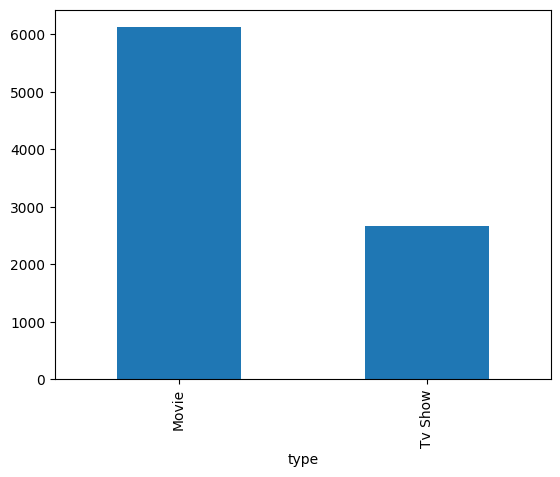

In [16]:
df['type'].value_counts().plot(kind='bar')

In [17]:
df['type'].value_counts(normalize=True) * 100

,proportion
type,
Movie,69.692833
Tv Show,30.307167


In [18]:
print(df['type'].value_counts())
print(df['type'].value_counts(normalize=True) * 100)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64
type
Movie      69.692833
Tv Show    30.307167
Name: proportion, dtype: float64


## **Task . 3**

In [19]:
df['country'] = df['country'].str.split(', ')
df = df.explode('country')
df['country'] = df['country'].str.strip()

In [20]:
country_count = df['country'].value_counts()

In [21]:
country_count.head(10)

,count
country,
United States,3240
India,1057
United Kingdom,638
Pakistan,421
Not Given,287
Canada,271
Japan,259
South Korea,214
France,213


<Axes: xlabel='country'>

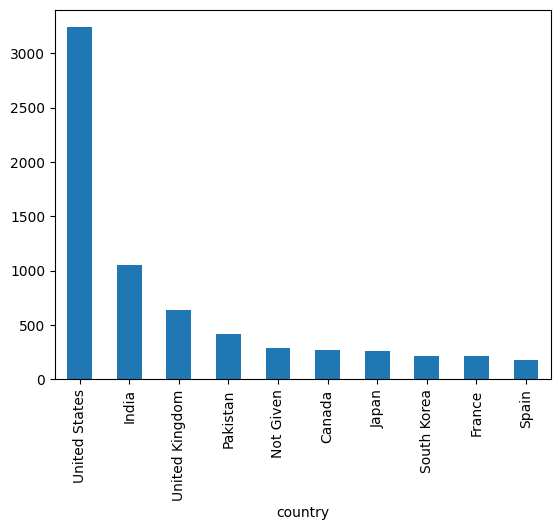

In [22]:
country_count.head(10).plot(kind='bar')

In [23]:
print("Top Content-Producing Countries:")
print(country_count.head(10))

Top Content-Producing Countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


In [24]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')

## Task *.4*

In [25]:
df = df.sort_values('release_year')

In [27]:
yearly_releases = df['release_year'].value_counts().sort_index()

In [28]:
yearly_releases.diff()

,count
release_year,
1925,NaN
1942,1.0
1943,1.0
1944,0.0
1945,1.0
...,...
2017,129.0
2018,116.0
2019,-116.0


<Axes: xlabel='release_year'>

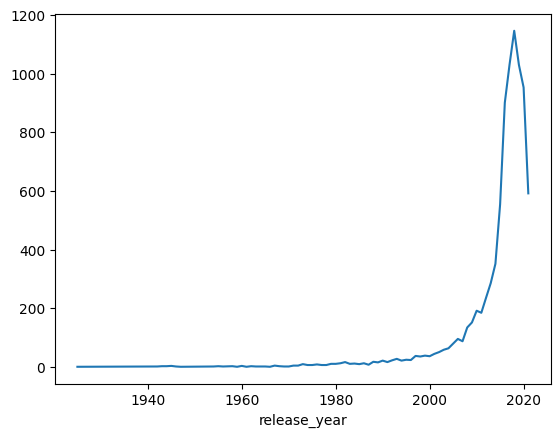

In [29]:
yearly_releases.plot(kind='line')

In [30]:
print(yearly_releases)
print("Highest releases:", yearly_releases.idxmax())
print("Lowest releases:", yearly_releases.idxmin())

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64
Highest releases: 2018
Lowest releases: 1925


## **Task .5**

In [32]:
df['rating'].value_counts()

,count
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


In [33]:
df['listed_in'].str.split(', ').explode().value_counts().head(10)

,count
listed_in,
International Movies,2752
Dramas,2426
Comedies,1674
International TV Shows,1349
Documentaries,869
Action & Adventure,859
TV Dramas,762
Independent Movies,756
Children & Family Movies,641


In [34]:
df.groupby(['type', 'rating']).size().unstack(fill_value=0)

rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR
type,,,,,,,,,,,,,,
Movie,41,3,75,287,490,797,1427,126,2062,540,131,139,5,3
Tv Show,0,0,4,0,0,2,730,94,1143,321,175,194,1,0


In [35]:
import plotly.express as px
px.bar(df, x='rating', color='type').show()

In [37]:
print("Most common ratings:\n", df['rating'].value_counts().head())
print("Most common genres:\n", df['listed_in'].str.split(', ').explode().value_counts().head(10))

Most common ratings:
 rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64
Most common genres:
 listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


# Task **.6**

In [38]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 8790 entries, 421 to 23
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 755.4+ KB


,0
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


In [39]:
df['type'].value_counts()
df['country'].value_counts()
df['release_year'].value_counts()
df['rating'].value_counts()

,count
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


<Axes: xlabel='release_year'>

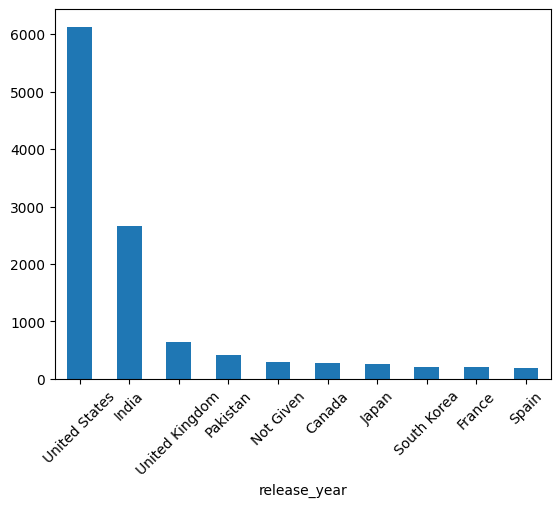

In [43]:
df['type'].value_counts().plot(kind='bar', rot=45)

df['country'].value_counts().head(10).plot(kind='bar', rot=45)

df['release_year'].value_counts().sort_index().plot(kind='line', rot=45)

In [41]:
df['type'].value_counts()
df['country'].value_counts().head(10)
df['release_year'].value_counts().sort_index()

,count
release_year,
1925,1
1942,2
1943,3
1944,3
1945,4
...,...
2017,1030
2018,1146
2019,1030


In [42]:
df.to_csv('/content/Final_Analytical_Report.csv', index=False)